# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [148]:

class Deck:
    SUITS = ["Hearts", "Diamonds", "Clubs", "Spades"]
    RANKS = ["A", "2", "3", "4", "5", "6", "7",
             "8", "9", "10", "J", "Q", "K"]

    def __init__(self, num_decks=6):
        if num_decks < 1:
            raise ValueError("Use at least one deck.")

        self.num_decks = num_decks
        self.plastic_card = object()
        self.cards = []
        self.shuffle_count = 0

        self._build_shoe()

    def _build_shoe(self):
        self.cards = [
            Card(rank, suit)
            for _ in range(self.num_decks)
            for suit in self.SUITS
            for rank in self.RANKS
        ]

        random.shuffle(self.cards)

        position = random.randrange(1, len(self.cards))
        self.cards.insert(position, self.plastic_card)

        self.shuffle_count += 1

    def shuffle(self):
       
        self._build_shoe()

    def draw_card(self):
        while True:
            if not self.cards:
                self.shuffle()

            card = self.cards.pop(0)

            if card is self.plastic_card:
                self.shuffle()
                continue

            return card

    def cards_remaining(self):
        return sum(
            card is not self.plastic_card
            for card in self.cards
        )


In [149]:
card1 = Card("A", "Hearts")
print(card1)

deck = Deck(num_decks=6)
print("Number of real cards:", deck.cards_remaining())
print("Example drawn card:", deck.draw_card())

A of Hearts
Number of real cards: 312
Example drawn card: 5 of Hearts


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [150]:
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        pass

    def value(self):
        pass

    def is_bust(self):
        pass

    def is_blackjack(self):
        pass


class Player:
    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = Hand()
        self.bet = 0

    def place_bet(self, amount):
        pass

    def receive(self, card):
        pass

    def wants_hit(self, game):
        pass


class HumanPlayer(Player):
    def wants_hit(self, game):
        pass


class DealerPlayer(Player):
    def wants_hit(self, game):
        pass


class BlackjackGame:
    def __init__(self, players, num_decks=6):
        self.deck = Deck(num_decks)
        self.players = players
        self.dealer = DealerPlayer("Dealer")
        self.running_count = 0

    def play_round(self):
        pass

    def play(self, rounds=1):
        pass

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [151]:
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        self.cards.append(card)

    def value(self):
        total = 0
        aces = 0

        for card in self.cards:
            if card.rank == "A":
                total += 11
                aces += 1
            elif card.rank in ["J", "Q", "K"]:
                total += 10
            else:
                total += int(card.rank)

        while total > 21 and aces > 0:
            total -= 10
            aces -= 1

        return total

    def is_bust(self):
        return self.value() > 21

    def is_blackjack(self):
        return len(self.cards) == 2 and self.value() == 21

    def __str__(self):
        return f"{self.cards} (value={self.value()})"


class Player:
    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = Hand()
        self.bet = 0

    def place_bet(self, amount=1):
        self.bet = min(amount, self.chips)
        self.chips -= self.bet

    def receive(self, card):
        self.hand.add_card(card)

    def wants_hit(self, game):
      
        return self.hand.value() < 17


class HumanPlayer(Player):
    def wants_hit(self, game):
        while True:
            answer = input(
                f"{self.name}, hand: {self.hand}\n"
                "hit or stand? (h/s): "
            ).strip().lower()

            if answer in ["h", "hit"]:
                return True

            if answer in ["s", "stand"]:
                return False

            print("Enter h to hit or s to stand.")


class DealerPlayer(Player):
    def wants_hit(self, game):
        return self.hand.value() <= 16


class CountingPlayer(Player):
    def __init__(self, name, chips=100, threshold=0):
        super().__init__(name, chips)
        self.threshold = threshold

    def wants_hit(self, game):
        value = self.hand.value()

        if value < 12:
            return True

        if value >= 17:
            return False

        return game.running_count <= self.threshold


class BlackjackGame:
    def __init__(self, players, num_decks=6, verbose=True):
        self.deck = Deck(num_decks)
        self.players = players
        self.dealer = DealerPlayer("Dealer")
        self.running_count = 0
        self.verbose = verbose
        self.round_number = 0

    def card_count_value(self, card):
        if card.rank in ["2", "3", "4", "5", "6"]:
            return 1
        elif card.rank in ["7", "8", "9"]:
            return 0
        else:
            return -1

    def deal_visible(self, player):
        card = self.deck.draw_card()
        player.receive(card)
        self.running_count += self.card_count_value(card)

    def play_round(self):
        active_players = [
            p for p in self.players if p.chips > 0
        ]

        if not active_players:
            return

        self.round_number += 1
        everyone = active_players + [self.dealer]

        for player in everyone:
            player.hand = Hand()

        for player in active_players:
            player.place_bet(1)

        for _ in range(2):
            for player in everyone:
                self.deal_visible(player)

        if self.verbose:
            print(f"\n--- Round {self.round_number} ---")
            for player in active_players:
                print(player.name, player.hand)
            print("Dealer:", self.dealer.hand)

        for player in active_players:
            while (
                not player.hand.is_bust()
                and player.wants_hit(self)
            ):
                self.deal_visible(player)

                if self.verbose:
                    print("Hit:", player.name, player.hand)

        while (
            not self.dealer.hand.is_bust()
            and self.dealer.wants_hit(self)
        ):
            self.deal_visible(self.dealer)

        dealer_value = self.dealer.hand.value()
        dealer_bust = self.dealer.hand.is_bust()
        dealer_blackjack = self.dealer.hand.is_blackjack()

        if self.verbose:
            print("Final dealer hand:", self.dealer.hand)


        for player in active_players:
            value = player.hand.value()
            bet = player.bet

            if player.hand.is_bust():
                result = "loss"

            elif player.hand.is_blackjack():
                if dealer_blackjack:
                    player.chips += bet
                    result = "push"
                else:
                
                    player.chips += bet * 2.5
                    result = "blackjack"

            elif dealer_blackjack:
                result = "loss"

            elif dealer_bust or value > dealer_value:
                player.chips += bet * 2
                result = "win"

            elif value == dealer_value:
                player.chips += bet
                result = "push"

            else:
                result = "loss"

            if self.verbose:
                print(
                    f"{player.name}: {result}; "
                    f"chips = {player.chips:g}"
                )

    def play(self, rounds=1):
        for _ in range(rounds):
            if not any(p.chips > 0 for p in self.players):
                break

            self.play_round()

        return {p.name: p.chips for p in self.players}

5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [152]:
random.seed(16)

players = [
    Player("Computer 1", chips=20),
    Player("Computer 2", chips=20),
    Player("Computer 3", chips=20)
]

game = BlackjackGame(
    players=players,
    num_decks=6,
    verbose=True
)

final_chips = game.play(rounds=5)

print("\nFinal results:")

for name, chips in final_chips.items():
    print(f"{name}: {chips} chips")


--- Round 1 ---
Computer 1 [A of Diamonds, 9 of Clubs] (value=20)
Computer 2 [5 of Spades, 8 of Clubs] (value=13)
Computer 3 [K of Clubs, 4 of Spades] (value=14)
Dealer: [10 of Clubs, 7 of Clubs] (value=17)
Hit: Computer 2 [5 of Spades, 8 of Clubs, A of Spades] (value=14)
Hit: Computer 2 [5 of Spades, 8 of Clubs, A of Spades, 2 of Diamonds] (value=16)
Hit: Computer 2 [5 of Spades, 8 of Clubs, A of Spades, 2 of Diamonds, 4 of Diamonds] (value=20)
Hit: Computer 3 [K of Clubs, 4 of Spades, Q of Clubs] (value=24)
Final dealer hand: [10 of Clubs, 7 of Clubs] (value=17)
Computer 1: win; chips = 21
Computer 2: win; chips = 21
Computer 3: loss; chips = 19

--- Round 2 ---
Computer 1 [5 of Spades, A of Hearts] (value=16)
Computer 2 [2 of Clubs, K of Hearts] (value=12)
Computer 3 [3 of Hearts, 5 of Spades] (value=8)
Dealer: [Q of Spades, 9 of Diamonds] (value=19)
Hit: Computer 1 [5 of Spades, A of Hearts, 5 of Spades] (value=21)
Hit: Computer 2 [2 of Clubs, K of Hearts, J of Clubs] (value=22)
H

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [153]:
def count_card(card):
    if card.rank in ["2", "3", "4", "5", "6"]:
        return 1
    elif card.rank in ["7", "8", "9"]:
        return 0
    else:
        return -1


test_cards = [
    Card("2", "Hearts"),
    Card("7", "Spades"),
    Card("K", "Diamonds"),
    Card("A", "Clubs")
]

for card in test_cards:
    print(card, "has count value", count_card(card))

2 of Hearts has count value 1
7 of Spades has count value 0
K of Diamonds has count value -1
A of Clubs has count value -1


7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [154]:
class DealerStrategyPlayer(Player):
    """Hits below 17 and stands at 17 or above."""

    def wants_hit(self, game):
        total = 0
        aces = 0

        for card in self.hand.cards:
            rank = str(card.rank)

            if rank in ["A", "Ace"]:
                total += 11
                aces += 1
            elif rank in ["J", "Q", "K", "Jack", "Queen", "King"]:
                total += 10
            else:
                total += int(rank)

        while total > 21 and aces > 0:
            total -= 10
            aces -= 1

        return total < 17

8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?



--- Round 1 ---
Counting Player [9 of Hearts, 6 of Diamonds] (value=15)
Player 2 [9 of Clubs, 5 of Clubs] (value=14)
Player 3 [Q of Hearts, 7 of Clubs] (value=17)
Player 4 [8 of Spades, 7 of Spades] (value=15)
Dealer: [2 of Spades, 2 of Diamonds] (value=4)
Hit: Player 2 [9 of Clubs, 5 of Clubs, 7 of Spades] (value=21)
Hit: Player 4 [8 of Spades, 7 of Spades, 8 of Spades] (value=23)
Final dealer hand: [2 of Spades, 2 of Diamonds, 7 of Spades, 9 of Diamonds] (value=20)
Counting Player: loss; chips = 99
Player 2: win; chips = 101
Player 3: loss; chips = 99
Player 4: loss; chips = 99

--- Round 2 ---
Counting Player [6 of Spades, 8 of Diamonds] (value=14)
Player 2 [3 of Spades, J of Clubs] (value=13)
Player 3 [2 of Diamonds, Q of Clubs] (value=12)
Player 4 [5 of Hearts, 2 of Clubs] (value=7)
Dealer: [8 of Hearts, 4 of Hearts] (value=12)
Hit: Player 2 [3 of Spades, J of Clubs, J of Spades] (value=23)
Hit: Player 3 [2 of Diamonds, Q of Clubs, 8 of Hearts] (value=20)
Hit: Player 4 [5 of Hear

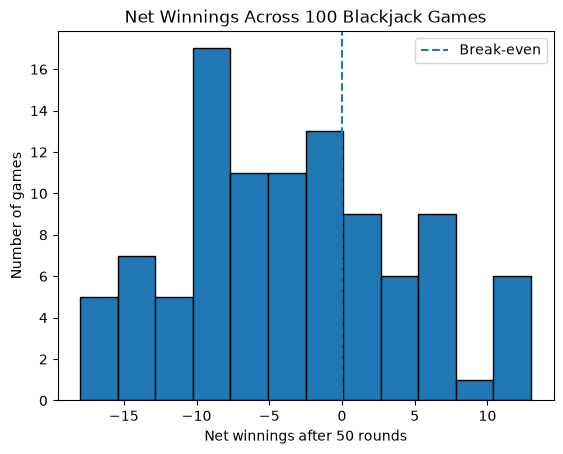

In [155]:

import statistics
import matplotlib.pyplot as plt

starting_chips = 100
rounds = 50
games = 100
threshold = 0

ending_chips_list = []
net_winnings = []

for i in range(games):
    players = [
        CountingPlayer(
            "Counting Player",
            chips=starting_chips,
            threshold=threshold
        ),
        DealerStrategyPlayer("Player 2", chips=starting_chips),
        DealerStrategyPlayer("Player 3", chips=starting_chips),
        DealerStrategyPlayer("Player 4", chips=starting_chips)
    ]

    # Create a new game for each trial
    game = BlackjackGame(players)

    for _ in range(rounds):
        if players[0].chips <= 0:
            break
        game.play_round()

    # Save the counting player's results
    ending_chips = players[0].chips
    winnings = ending_chips - starting_chips

    ending_chips_list.append(ending_chips)
    net_winnings.append(winnings)

# Calculate statistics
average_ending = statistics.mean(ending_chips_list)
average_winnings = statistics.mean(net_winnings)
average_per_round = average_winnings / rounds

std_dev = statistics.stdev(net_winnings)

wins = sum(w > 0 for w in net_winnings)
losses = sum(w < 0 for w in net_winnings)
ties = sum(w == 0 for w in net_winnings)

probability_win = wins / games
probability_loss = losses / games
probability_tie = ties / games

print("Average ending chips:", average_ending)
print("Average net winnings per game:", average_winnings)
print("Average net winnings per round:", average_per_round)
print("Standard deviation:", std_dev)
print("Probability of winning:", probability_win)
print("Probability of losing:", probability_loss)
print("Probability of a tie:", probability_tie)

# Plot histogram
plt.hist(net_winnings, bins=12, edgecolor="black")
plt.axvline(0, linestyle="--", label="Break-even")
plt.xlabel("Net winnings after 50 rounds")
plt.ylabel("Number of games")
plt.title("Net Winnings Across 100 Blackjack Games")
plt.legend()
plt.show()


9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

In [156]:
#Threshold 1 performed the best, with average net winnings of -2.10 chips per game and a win probability of 33%.
#Threshold 3 had the highest win probability at 36%, but its average net winnings were lower at -2.42 chips per game. 
#Threshold 0 performed the worst, with average net winnings of -3.42 chips per game.

In [157]:

import statistics

starting_chips = 100
rounds = 50
games = 100

thresholds = [-1,0, 1, 2, 3, 4]
results = {}

for threshold in thresholds:
    all_winnings = []

    for i in range(games):
        players = [
            CountingPlayer(
                "Counting Player",
                chips=starting_chips,
                threshold=threshold
            ),
            DealerStrategyPlayer("Player 2", chips=starting_chips),
            DealerStrategyPlayer("Player 3", chips=starting_chips),
            DealerStrategyPlayer("Player 4", chips=starting_chips)
        ]

        game = BlackjackGame(players, verbose=False)

        for _ in range(rounds):
            if players[0].chips <= 0:
                break
            game.play_round()

        all_winnings.append(players[0].chips - starting_chips)

    results[threshold] = {
        "average": statistics.mean(all_winnings),
        "std_dev": statistics.stdev(all_winnings),
        "win": sum(w > 0 for w in all_winnings) / games,
        "loss": sum(w < 0 for w in all_winnings) / games,
        "tie": sum(w == 0 for w in all_winnings) / games
    }

print("THRESHOLD COMPARISON")

for threshold, result in results.items():
    print(f"\nThreshold: {threshold}")
    print("Average net winnings:", round(result["average"], 2))
    print("Standard deviation:", round(result["std_dev"], 2))
    print("Win probability:", f"{result['win']:.2%}")
    print("Loss probability:", f"{result['loss']:.2%}")
    print("Tie probability:", f"{result['tie']:.2%}")

best_threshold = max(results, key=lambda t: results[t]["average"])

print("\nBest tested threshold:", best_threshold)
print("Best average net winnings:",
      round(results[best_threshold]["average"], 2))


THRESHOLD COMPARISON

Threshold: -1
Average net winnings: -2.53
Standard deviation: 6.79
Win probability: 34.00%
Loss probability: 64.00%
Tie probability: 2.00%

Threshold: 0
Average net winnings: -2.5
Standard deviation: 6.85
Win probability: 37.00%
Loss probability: 60.00%
Tie probability: 3.00%

Threshold: 1
Average net winnings: -3.29
Standard deviation: 7.01
Win probability: 32.00%
Loss probability: 66.00%
Tie probability: 2.00%

Threshold: 2
Average net winnings: -3.73
Standard deviation: 6.72
Win probability: 30.00%
Loss probability: 68.00%
Tie probability: 2.00%

Threshold: 3
Average net winnings: -4.09
Standard deviation: 6.93
Win probability: 27.00%
Loss probability: 71.00%
Tie probability: 2.00%

Threshold: 4
Average net winnings: -3.25
Standard deviation: 6.94
Win probability: 31.00%
Loss probability: 68.00%
Tie probability: 1.00%

Best tested threshold: 0
Best average net winnings: -2.5


10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

In [158]:

class ConservativePlayer(Player):
    def wants_hit(self, game):
        return self.hand.value() < 17


In [159]:

import statistics

starting_chips = 100
rounds = 50
games = 100

strategy_results = {}

for strategy_name, strategy_class in [
    ("CountingPlayer", CountingPlayer),
    ("ConservativePlayer", ConservativePlayer)
]:
    all_winnings = []

    for i in range(games):
        players = [
            strategy_class("Test Player", chips=starting_chips),
            DealerStrategyPlayer("Player 2", chips=starting_chips),
            DealerStrategyPlayer("Player 3", chips=starting_chips),
            DealerStrategyPlayer("Player 4", chips=starting_chips)
        ]

        game = BlackjackGame(players, verbose=False)

        for _ in range(rounds):
            if players[0].chips <= 0:
                break
            game.play_round()

        all_winnings.append(players[0].chips - starting_chips)

    strategy_results[strategy_name] = {
        "average_winnings": statistics.mean(all_winnings),
        "win_probability": sum(w > 0 for w in all_winnings) / games,
        "loss_probability": sum(w < 0 for w in all_winnings) / games,
        "tie_probability": sum(w == 0 for w in all_winnings) / games
    }

for name, result in strategy_results.items():
    print(f"\n{name}")
    print("Average net winnings:", round(result["average_winnings"], 2))
    print("Win probability:", f"{result['win_probability']:.2%}")
    print("Loss probability:", f"{result['loss_probability']:.2%}")
    print("Tie probability:", f"{result['tie_probability']:.2%}")

print("\nComparison:")
difference = (
    strategy_results["ConservativePlayer"]["average_winnings"]
    - strategy_results["CountingPlayer"]["average_winnings"]
)
print("Conservative minus Counting average winnings:", round(difference, 2))



CountingPlayer
Average net winnings: -3.06
Win probability: 34.00%
Loss probability: 64.00%
Tie probability: 2.00%

ConservativePlayer
Average net winnings: -2.35
Win probability: 37.00%
Loss probability: 61.00%
Tie probability: 2.00%

Comparison:
Conservative minus Counting average winnings: 0.71
